# 📊 Ciclos Macro
Notebook 01: Preprocessing

## Preliminares

In [1]:
import pandas as pd
from src.extract import fetch_fred, fetch_prices
from src.preprocessing_functions import *
from src.config import clean_data_file, daily_cols, monthly_cols

### Extraer datos macro

In [2]:
df_macro = fetch_fred()
df_macro.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4442 entries, 2010-01-01 to 2026-10-22
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   real_yield_10y             4203 non-null   float64
 1   dxy_broad_goods            4181 non-null   float64
 2   vix_index                  4260 non-null   float64
 3   st_louis_financial_stress  877 non-null    float64
 4   industrial_production      201 non-null    float64
 5   unemployment_rate          200 non-null    float64
 6   cpi_headline               200 non-null    float64
 7   fed_funds_rate             201 non-null    float64
 8   m2_money_supply            200 non-null    float64
dtypes: float64(9)
memory usage: 347.0 KB


In [3]:
# Se remuestran a fin de mes aplicando lag de 1 periodo a series macro mensuales
df_macro_monthly = process_macro_to_monthly(df_raw=df_macro, daily_columns=daily_cols, monthly_columns=monthly_cols)
df_macro_monthly.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   real_yield_10y              201 non-null    float64
 1   dxy_broad_goods             201 non-null    float64
 2   vix_index                   201 non-null    float64
 3   st_louis_financial_stress   201 non-null    float64
 4   industrial_production_lag1  200 non-null    float64
 5   unemployment_rate_lag1      199 non-null    float64
 6   cpi_headline_lag1           199 non-null    float64
 7   fed_funds_rate_lag1         200 non-null    float64
 8   m2_money_supply_lag1        200 non-null    float64
dtypes: float64(9)
memory usage: 15.7 KB


In [4]:
# Mostrar missings iniciales
show_missings(df_macro_monthly)

unemployment_rate_lag1        0.009950
cpi_headline_lag1             0.009950
industrial_production_lag1    0.004975
fed_funds_rate_lag1           0.004975
m2_money_supply_lag1          0.004975
dtype: float64

In [5]:
# Ver datos faltantes
print(df_macro_monthly[df_macro_monthly["cpi_headline_lag1"].isna()])

            real_yield_10y  dxy_broad_goods  vix_index  \
date                                                     
2010-01-31            1.30          93.7638      24.62   
2025-11-30            1.79         121.0527      16.35   

            st_louis_financial_stress  industrial_production_lag1  \
date                                                                
2010-01-31                     0.0628                         NaN   
2025-11-30                    -0.3798                    101.2195   

            unemployment_rate_lag1  cpi_headline_lag1  fed_funds_rate_lag1  \
date                                                                         
2010-01-31                     NaN                NaN                  NaN   
2025-11-30                     NaN                NaN                 4.09   

            m2_money_supply_lag1  
date                              
2010-01-31                   NaN  
2025-11-30               22249.8  


In [6]:
# Se aplica forward fill y se mantienen missings iniciales
df_macro_monthly = df_macro_monthly.ffill(limit=1)
show_missings(df_macro_monthly)

industrial_production_lag1    0.004975
unemployment_rate_lag1        0.004975
cpi_headline_lag1             0.004975
fed_funds_rate_lag1           0.004975
m2_money_supply_lag1          0.004975
dtype: float64

### Extraer precios

In [7]:
df_prices = fetch_prices()

# Se elimina la fila del mes en curso
df_historical_prices = drop_incomplete_month(df_prices)

df_historical_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Freq: ME
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   oil     201 non-null    float64
 1   gold    201 non-null    float64
 2   spy     201 non-null    float64
dtypes: float64(3)
memory usage: 6.3 KB


### Unir datasets

In [8]:
df_merged = df_macro_monthly.join(df_historical_prices, how="inner")
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   real_yield_10y              201 non-null    float64
 1   dxy_broad_goods             201 non-null    float64
 2   vix_index                   201 non-null    float64
 3   st_louis_financial_stress   201 non-null    float64
 4   industrial_production_lag1  200 non-null    float64
 5   unemployment_rate_lag1      200 non-null    float64
 6   cpi_headline_lag1           200 non-null    float64
 7   fed_funds_rate_lag1         200 non-null    float64
 8   m2_money_supply_lag1        200 non-null    float64
 9   oil                         201 non-null    float64
 10  gold                        201 non-null    float64
 11  spy                         201 non-null    float64
dtypes: float64(12)
memory usage: 20.4 KB


## Feature Engineering

In [9]:
# Variaciones porcentuales mensuales
monthly_return_cols = [
    'oil',
    'gold',
    'spy',
    'dxy_broad_goods',
    'vix_index',
]
df_features = calculate_return(df_merged, cols=monthly_return_cols, periods=1)

# Variaciones porcentuales YoY
yearly_return_cols = [
    'oil',
    'gold',
    'spy',
    'cpi_headline_lag1',
    'industrial_production_lag1',
    'm2_money_supply_lag1'
]
df_features = calculate_return(df_features, cols=yearly_return_cols, periods=12)

# Cambios absolutos en variables originales porcentuales mensuales
monthly_yield_cols = [
    'real_yield_10y',
    'st_louis_financial_stress'
]
df_features = calculate_delta(df_features, cols=monthly_yield_cols, periods=1)

# Cambios absolutos YoY
yearly_yield_cols = [
    'unemployment_rate_lag1',
    'fed_funds_rate_lag1'
]
df_features = calculate_delta(df_features, cols=yearly_yield_cols, periods=12)

# Cambios absolutos QoQ: se aplica sobre las mismas columnas que el anual
df_features = calculate_delta(df_features, cols=yearly_yield_cols, periods=3)

# Se eliminan columnas base originales no estacionarias
base_cols_to_drop = [
    'oil',
    'gold',
    'spy',
    'dxy_broad_goods',
    'cpi_headline_lag1',
    'industrial_production_lag1',
    'unemployment_rate_lag1',
    'm2_money_supply_lag1',
    'fed_funds_rate_lag1'
]
df_features = df_features.drop(columns=base_cols_to_drop)

df_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   real_yield_10y                       201 non-null    float64
 1   vix_index                            201 non-null    float64
 2   st_louis_financial_stress            201 non-null    float64
 3   oil_ret_1m                           200 non-null    float64
 4   gold_ret_1m                          200 non-null    float64
 5   spy_ret_1m                           200 non-null    float64
 6   dxy_broad_goods_ret_1m               200 non-null    float64
 7   vix_index_ret_1m                     200 non-null    float64
 8   oil_ret_12m                          189 non-null    float64
 9   gold_ret_12m                         189 non-null    float64
 10  spy_ret_12m                          189 non-null    float64
 11  cpi_headline_

In [10]:
# Se eliminan missings iniciales luego del calculo de las diferencias
df_features = df_features.dropna()

## EDA

In [11]:
df_features.describe()

,real_yield_10y,vix_index,st_louis_financial_stress,oil_ret_1m,gold_ret_1m,spy_ret_1m,dxy_broad_goods_ret_1m,vix_index_ret_1m,oil_ret_12m,gold_ret_12m,spy_ret_12m,cpi_headline_lag1_ret_12m,industrial_production_lag1_ret_12m,m2_money_supply_lag1_ret_12m,real_yield_10y_change_1m,st_louis_financial_stress_change_1m,unemployment_rate_lag1_change_12m,fed_funds_rate_lag1_change_12m,unemployment_rate_lag1_change_3m,fed_funds_rate_lag1_change_3m
count,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000
mean,0.560904,18.196383,-0.236680,0.006976,0.007209,0.010349,0.001724,0.027152,0.055635,0.099641,0.129915,0.026795,0.007476,0.064943,0.009840,-0.002932,-0.338298,0.228138,-0.085638,0.054947
std,0.956110,6.419249,0.619414,0.122351,0.047212,0.041037,0.016296,0.255112,0.388819,0.191847,0.117822,0.019071,0.035451,0.057040,0.207667,0.538071,1.943045,1.219192,1.360739,0.385894
min,-1.160000,9.510000,-0.922000,-0.542449,-0.121212,-0.129987,-0.037838,-0.458969,-0.705210,-0.282362,-0.194816,-0.002299,-0.173183,-0.046407,-0.510000,-2.955300,-8.700000,-2.370000,-4.800000,-1.530000
25%,-0.007500,13.772500,-0.620400,-0.057092,-0.021294,-0.011585,-0.010062,-0.144775,-0.170452,-0.034175,0.055726,0.015966,-0.008247,0.040317,-0.110000,-0.187200,-0.900000,-0.110000,-0.300000,-0.020000
50%,0.480000,16.465000,-0.337600,0.008885,0.004777,0.014755,-0.000691,-0.009129,-0.012969,0.069318,0.140006,0.022683,0.012052,0.057929,-0.020000,-0.018000,-0.500000,0.030000,-0.100000,0.000000
75%,1.265000,19.887500,-0.042450,0.061544,0.037497,0.033195,0.013591,0.131685,0.202247,0.225978,0.195025,0.031789,0.027285,0.072356,0.130000,0.168300,0.000000,0.585000,0.000000,0.120000
max,2.930000,53.540000,5.386400,0.883758,0.122950,0.126984,0.060224,1.345710,2.374735,0.842338,0.537653,0.089794,0.165521,0.267776,1.010000,4.701800,11.100000,4.500000,11.200000,1.560000


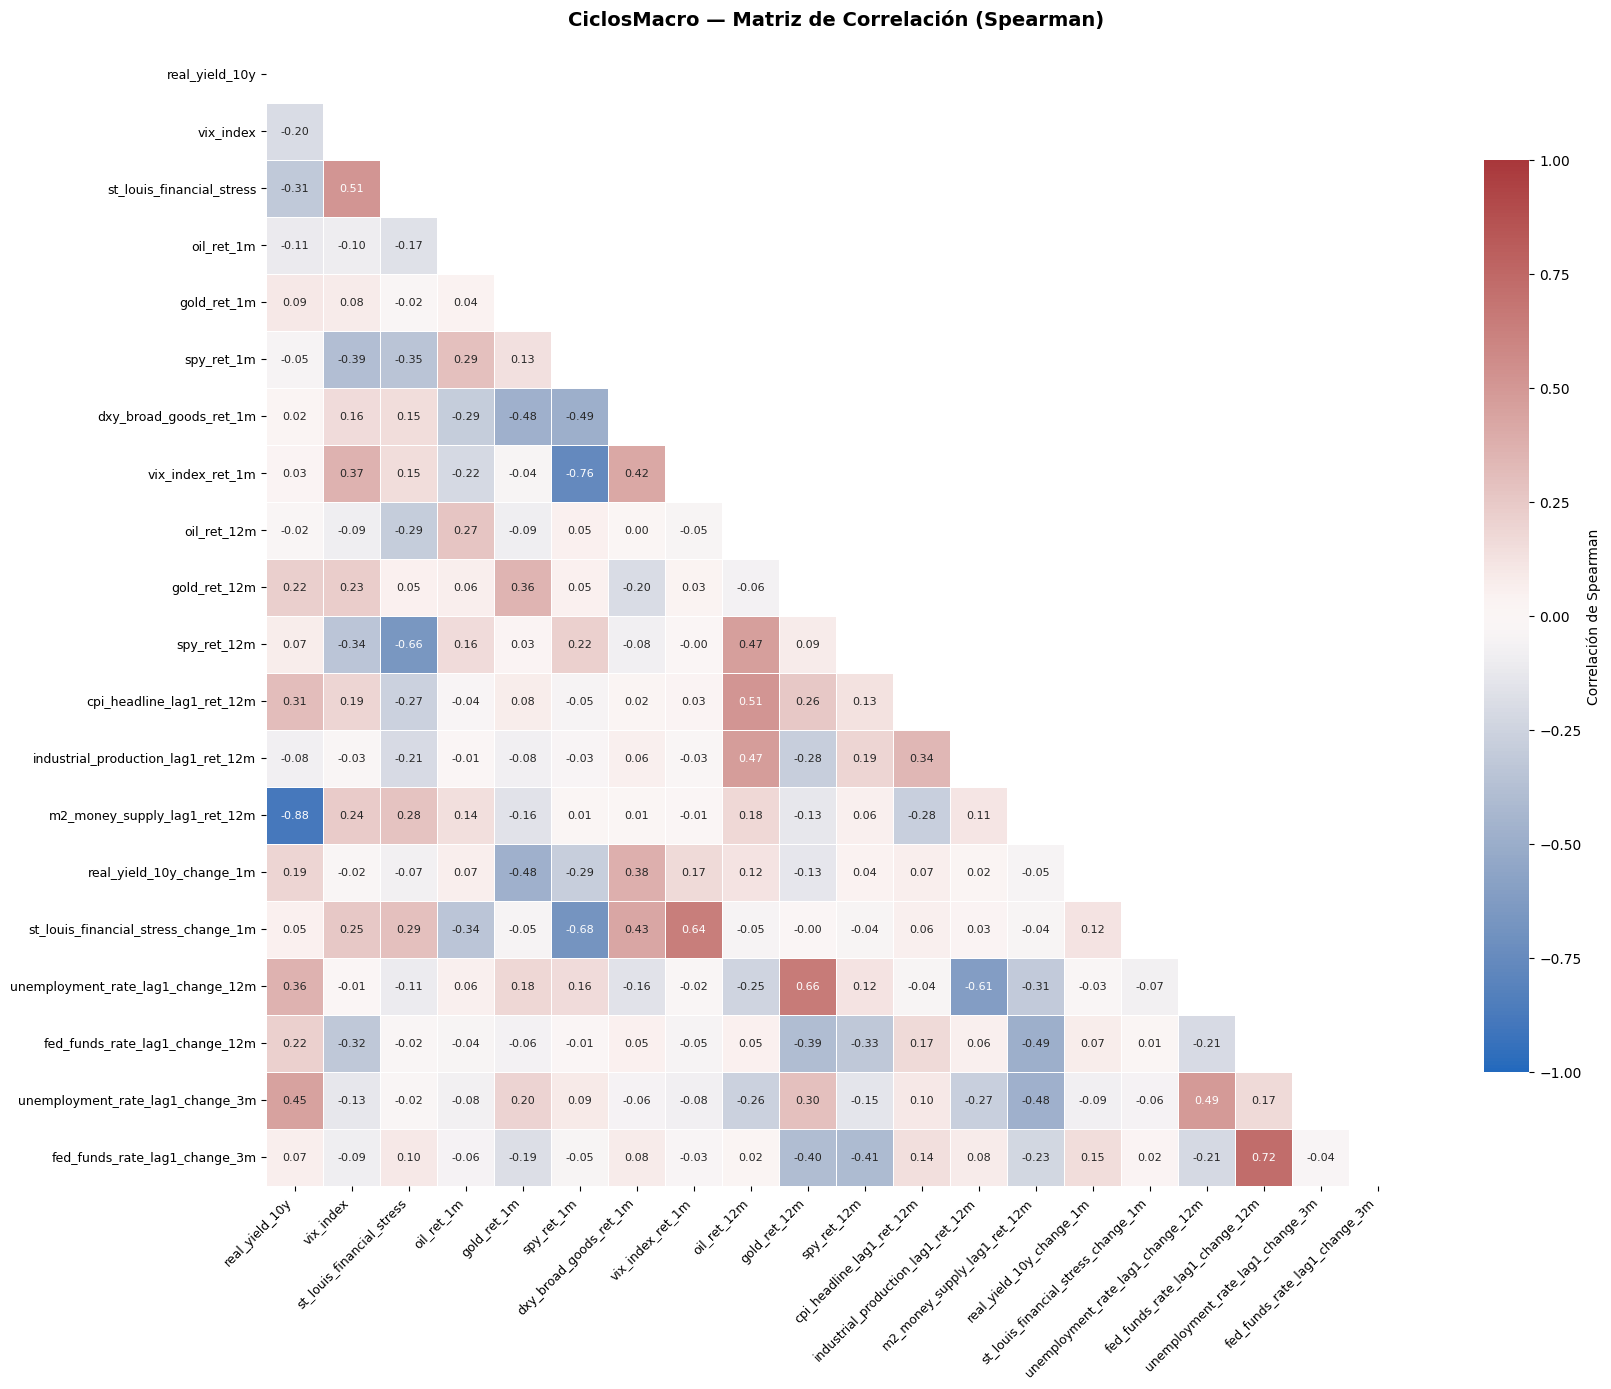


--- Pares con mayor redundancia / correlación extrema ---
                              feature_1                           feature_2  correlation
0          m2_money_supply_lag1_ret_12m                      real_yield_10y    -0.883658
1                      vix_index_ret_1m                          spy_ret_1m    -0.758423
2         fed_funds_rate_lag1_change_3m      fed_funds_rate_lag1_change_12m     0.721572
3   st_louis_financial_stress_change_1m                          spy_ret_1m    -0.683569
4                           spy_ret_12m           st_louis_financial_stress    -0.657190
5     unemployment_rate_lag1_change_12m                        gold_ret_12m     0.655398
6   st_louis_financial_stress_change_1m                    vix_index_ret_1m     0.640567
7     unemployment_rate_lag1_change_12m  industrial_production_lag1_ret_12m    -0.612396
8             st_louis_financial_stress                           vix_index     0.512481
9             cpi_headline_lag1_ret_12m            

In [12]:
# Matriz de correlaciones
corr_matrix, top_redundant_pairs = plot_correlation_matrix(
    df=df_features,
    method="spearman",
    figsize=(18, 14),
    top_n_pairs=12,
)

print("\n--- Pares con mayor redundancia / correlación extrema ---")
print(top_redundant_pairs.to_string())

* `m2_money_supply_lag1_ret_12m` vs `real_yield_10y`: Refleja la postura monetaria de la Reserva Federal. Una expansión monetaria acelerada deprime las tasas reales, mientras que una contracción de liquidez dispara los rendimientos de los bonos.
* `vix_index_ret_1m` vs  `spy_ret_1m` / `st_louis_financial_stress_change_1m` vs `spy_ret_1m` / `spy_ret_12m` vs `st_louis_financial_stress` / `st_louis_financial_stress_change_1m` vs `vix_index_ret_1m` - Bloque de Aversión al Riesgo y Estrés. El mercado de renta variable reacciona de forma simétrica a la volatilidad implícita y a la tensión en los mercados de crédito.
* `fed_funds_rate_lag1_change_3m` vs `fed_funds_rate_lag1_change_12m`: Colinealidad inducida por construcción temporal. Si la Fed esta subiendo tasas en 12 meses, la variación de los últimos 3 meses también sera positiva.
* `unemployment_rate_lag1_change_12m` vs `gold_ret_12m`: Cobertura macro. El aumento sostenido del desempleo indica riesgo recesivo o estanflacionario, impulsando la demanda de oro como refugio.
* `unemployment_rate_lag1_change_12m` vs `industrial_production_lag1_ret_12m`: Ley de Okun empírica. Cuando la producción industrial colapsa año contra año, el desempleo se acelera en la misma proporción.
* `st_louis_financial_stress` vs `vix_index`:  Que el VIX y el índice de Saint Louis solo tengan un 51% de correlación señala que aportan información complementaria.
* `cpi_headline_lag1_ret_12m` vs `oil_ret_12m`: El petróleo como vector principal del componente energético en el IPC general.

Luego de analizar los 3 pares con mayor correlación, se determina:
* **Par 0**: A pesar de exhibir una correlación lineal pronunciada ($-0.88$), se decide conservar tanto `m2_money_supply_lag1_ret_12m` como `real_yield_10y`, porque ambas métricas capturan dimensiones económicas ortogonales de la postura monetaria: mientras la masa monetaria M2 mide la oferta agregada de liquidez en el sistema, la tasa real a 10 años refleja el costo efectivo del capital y las expectativas de crecimiento ajustadas por inflación, permitiendo a PCA comprimir esta relación macroeconómica sin pérdida de señal sustancial. 
* **Par 1**: De forma similar, se mantiene el Par 1 (`vix_index_ret_1m` vs. `spy_ret_1m`, con $-0.76$) dado que representan la rentabilidad mensual de la renta variable y la volatilidad implícita esperada, constituyendo el núcleo del factor de apetito por riesgo (Risk-On / Risk-Off). 
* **Par 2**: (`fed_funds_rate_lag1_change_3m` vs. `fed_funds_rate_lag1_change_12m`, con $+0.72$), la asociación se origina por una redundancia temporal artificial al medir la misma tasa bajo dos ventanas superpuestas; por ello, se elimina la variación de corto plazo (3 meses) para evitar un sobrepeso artificial de la política monetaria sobre los primeros autovectores de PCA, preservando la métrica de 12 meses como el indicador estructural del ciclo de ajuste o flexibilización de la Reserva Federal.

In [ ]:
# Se elimina la columna redundante
df_features.drop('fed_funds_rate_lag1_change_3m', axis=1, inplace=True)

In [16]:
# Ver asimetrías
show_asymmetry(df_features)

unemployment_rate_lag1_change_3m       5.156784
st_louis_financial_stress              4.676656
st_louis_financial_stress_change_1m    2.435167
oil_ret_12m                            2.040601
vix_index                              2.014479
oil_ret_1m                             1.812867
unemployment_rate_lag1_change_12m      1.781254
cpi_headline_lag1_ret_12m              1.507277
vix_index_ret_1m                       1.453209
fed_funds_rate_lag1_change_12m         1.438931
m2_money_supply_lag1_ret_12m           1.429598
real_yield_10y_change_1m               0.882339
gold_ret_12m                           0.759939
dxy_broad_goods_ret_1m                 0.340516
real_yield_10y                         0.234497
spy_ret_12m                           -0.010806
gold_ret_1m                           -0.072571
spy_ret_1m                            -0.325387
industrial_production_lag1_ret_12m    -0.739475


Cont


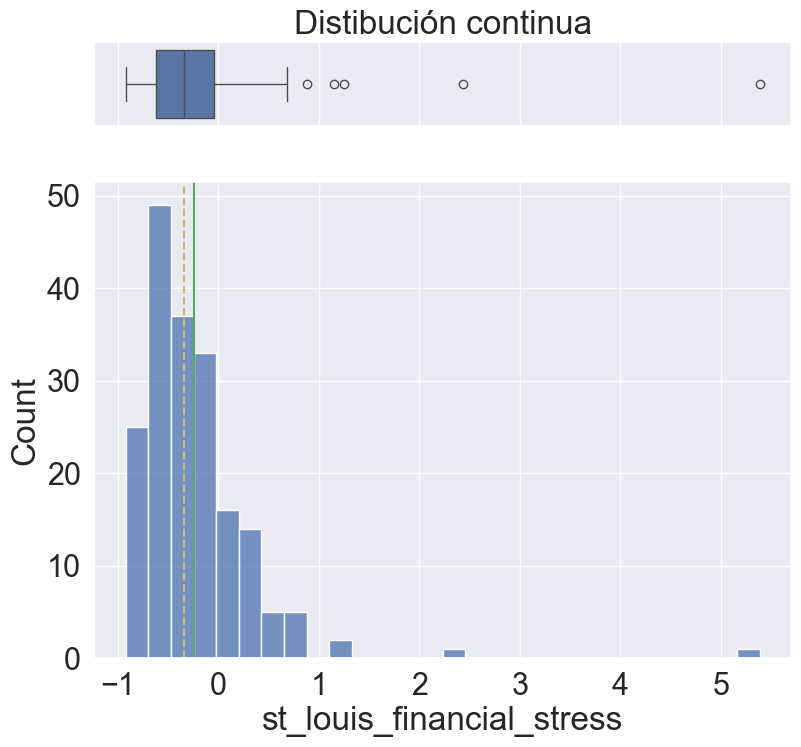

In [ ]:
# Graficar columna
col = 'st_louis_financial_stress'
plot_col(df_features[col])

## Transformaciones

In [17]:
# Yeo-Johnson 
yeo_cols = [
    'unemployment_rate_lag1_change_3m',
    'st_louis_financial_stress'
    ]
df_transformed = yeo_transform(df_features, cols=yeo_cols)
show_asymmetry(df_transformed)

st_louis_financial_stress_change_1m     2.435167
oil_ret_12m                             2.040601
vix_index                               2.014479
oil_ret_1m                              1.812867
unemployment_rate_lag1_change_12m       1.781254
cpi_headline_lag1_ret_12m               1.507277
vix_index_ret_1m                        1.453209
fed_funds_rate_lag1_change_12m          1.438931
m2_money_supply_lag1_ret_12m            1.429598
real_yield_10y_change_1m                0.882339
gold_ret_12m                            0.759939
dxy_broad_goods_ret_1m                  0.340516
real_yield_10y                          0.234497
st_louis_financial_stress_yeo           0.121882
spy_ret_12m                            -0.010806
gold_ret_1m                            -0.072571
spy_ret_1m                             -0.325387
industrial_production_lag1_ret_12m     -0.739475
unemployment_rate_lag1_change_3m_yeo   -1.090552


Cont


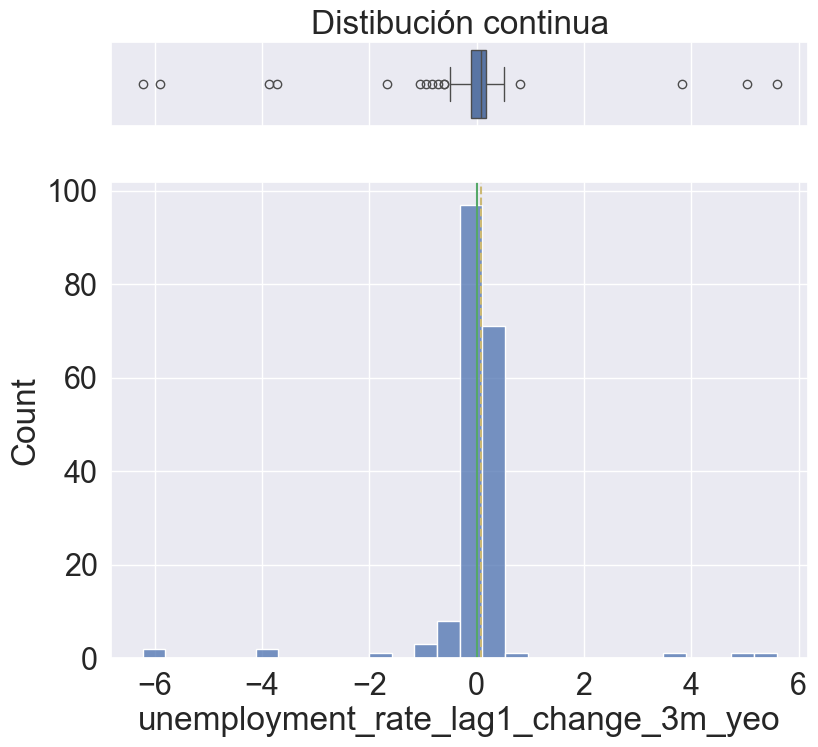

In [18]:
# Visualizar post transformación
col = 'unemployment_rate_lag1_change_3m_yeo'
plot_col(df_transformed[col])

In [19]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 188 entries, 2011-02-28 to 2026-09-30
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   real_yield_10y                        188 non-null    float64
 1   vix_index                             188 non-null    float64
 2   oil_ret_1m                            188 non-null    float64
 3   gold_ret_1m                           188 non-null    float64
 4   spy_ret_1m                            188 non-null    float64
 5   dxy_broad_goods_ret_1m                188 non-null    float64
 6   vix_index_ret_1m                      188 non-null    float64
 7   oil_ret_12m                           188 non-null    float64
 8   gold_ret_12m                          188 non-null    float64
 9   spy_ret_12m                           188 non-null    float64
 10  cpi_headline_lag1_ret_12m             188 non-null    float64
 11  

## Guardar fichero de datos limpios

In [21]:
# Asegurar que los directorios existan
clean_data_file.parent.mkdir(parents=True, exist_ok=True)

# Guardar el dataframe
df_transformed.to_parquet(clean_data_file)
print("Fichero guardado.\nContinuar con el notebook 02_Modeling para la fase siguiente.")


Fichero guardado.
Continuar con el notebook 02_Modeling para la fase siguiente.
